Homework 4, problem 3, part c

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
# parameters
N = 500
alphas = np.arange(0.02, 0.63, 0.04)
num_cues = 10

fraction_unstable_sim = []
fraction_unstable_theory = []
mean_overlaps = []

In [3]:
for alpha in alphas:
    P = int(round(alpha * N))
    
    # draw a pattern set of P random patterns of size N with entries in {-1, 1}
    patterns = np.random.choice([-1, 1], size=(P, N))
    
    # Hebbian rule
    W = (patterns.T @ patterns) / N
    np.fill_diagonal(W, 0)
    
    # measure fraction of unstable bits
    h = W @ patterns.T  # shape: (N, P)
    unstable = (patterns.T * h) < 0
    frac_unstable = np.mean(unstable)
    fraction_unstable_sim.append(frac_unstable)
    
    # compare with theoretical prediction
    fraction_unstable_theory.append(norm.cdf(-1.0 / np.sqrt(alpha)))
    
    # test recall
    overlaps_for_alpha = []
    for _ in range(num_cues):
        mu_idx = np.random.randint(0, P)
        original_pattern = patterns[mu_idx].copy()
        
        s = original_pattern.copy()
        num_flips = int(0.1 * N) # 10%
        flip_indices = np.random.choice(N, num_flips, replace=False)
        s[flip_indices] *= -1
        
        # update
        converged = False
        while not converged:
            s_old = s.copy()
            update_order = np.random.permutation(N)
            for i in update_order:
                hi = np.dot(W[i], s)
                s[i] = 1 if hi >= 0 else -1  # sgn(0) = 1
            
            if np.array_equal(s, s_old):
                converged = True
                
        m = np.dot(original_pattern, s) / N
        overlaps_for_alpha.append(m)
        
    mean_overlaps.append(np.mean(overlaps_for_alpha))

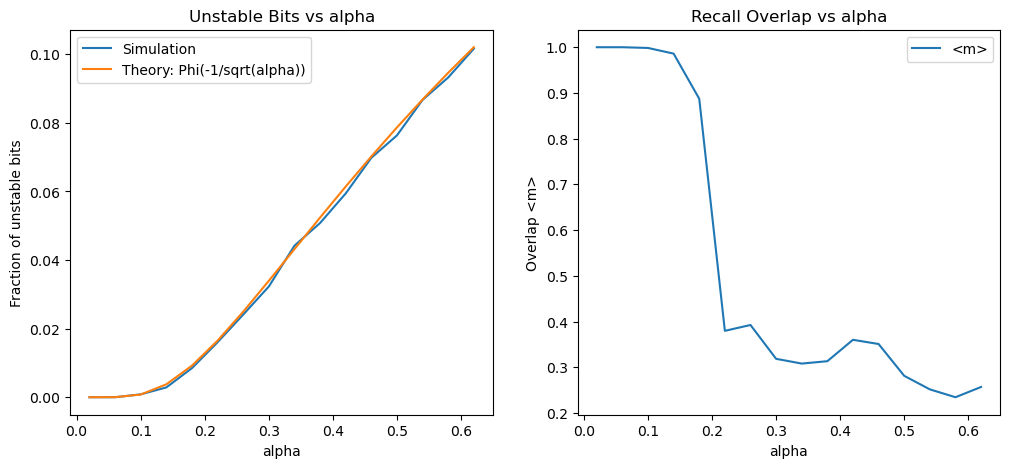

In [6]:
# visualization
plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.plot(alphas, fraction_unstable_sim, label = 'Simulation')
plt.plot(alphas, fraction_unstable_theory, label = 'Theory: Phi(-1/sqrt(alpha))')
plt.xlabel('alpha')
plt.ylabel('Fraction of unstable bits')
plt.legend()
plt.title('Unstable Bits vs alpha')

plt.subplot(1, 2, 2)
plt.plot(alphas, mean_overlaps, label = '<m>')
plt.xlabel('alpha')
plt.ylabel('Overlap <m>')
plt.title('Recall Overlap vs alpha')
plt.legend()

plt.show()